In [20]:
# ======================
# Core Libraries
# ======================
import numpy as np
import pandas as pd

# ======================
# Visualization (EDA)
# ======================
import matplotlib.pyplot as plt
import seaborn as sns

# ======================
# Data Spling
# ======================
from sklearn.model_selection import train_test_split

# ======================
# Preprocessing
# ======================
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.preprocessing import OneHotEncoder, LabelEncoder
from sklearn.impute import SimpleImputer

# ======================
# Pipeline & Column Transformer
# ======================
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

# ======================
# Warnings
# ======================
import warnings
warnings.filterwarnings('ignore')

In [21]:
# ============================================
# Data Loading and Full Data Overview
# ============================================

RANDOM_STATE = 42

file_path = r"E:\Advanced ML 2025 Hamed Mamani\ML project April 2026\archive\heart_disease.csv"

df = pd.read_csv(file_path)

# Preview
display(df.head())

# Info (ساختار کلی)
print("\n=== DataFrame Info ===")
df.info()

# Dataset shape
print("\n=== Dataset Shape ===")
print(f"Total Rows: {df.shape[0]}")
print(f"Total Columns: {df.shape[1]}")

# Column-wise detailed info
print("\n=== Column-wise Details ===")
df_info = pd.DataFrame({
    'Data Type': df.dtypes,
    'Non-Null Count': df.count(),
    'Missing Values': df.isnull().sum()
})

display(df_info)

,Age,Gender,Blood Pressure,Cholesterol Level,Exercise Habits,Smoking,Family Heart Disease,Diabetes,BMI,High Blood Pressure,...,High LDL Cholesterol,Alcohol Consumption,Stress Level,Sleep Hours,Sugar Consumption,Triglyceride Level,Fasting Blood Sugar,CRP Level,Homocysteine Level,Heart Disease Status
0,56.0,Male,153.0,155.0,High,Yes,Yes,No,24.991591,Yes,...,No,High,Medium,7.633228,Medium,342.0,NaN,12.969246,12.387250,No
1,69.0,Female,146.0,286.0,High,No,Yes,Yes,25.221799,No,...,No,Medium,High,8.744034,Medium,133.0,157.0,9.355389,19.298875,No
2,46.0,Male,126.0,216.0,Low,No,No,No,29.855447,No,...,Yes,Low,Low,4.440440,Low,393.0,92.0,12.709873,11.230926,No
3,32.0,Female,122.0,293.0,High,Yes,Yes,No,24.130477,Yes,...,Yes,Low,High,5.249405,High,293.0,94.0,12.509046,5.961958,No
4,60.0,Male,166.0,242.0,Low,Yes,Yes,Yes,20.486289,Yes,...,No,Low,High,7.030971,High,263.0,154.0,10.381259,8.153887,No



=== DataFrame Info ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Age                   9971 non-null   float64
 1   Gender                9981 non-null   object 
 2   Blood Pressure        9981 non-null   float64
 3   Cholesterol Level     9970 non-null   float64
 4   Exercise Habits       9975 non-null   object 
 5   Smoking               9975 non-null   object 
 6   Family Heart Disease  9979 non-null   object 
 7   Diabetes              9970 non-null   object 
 8   BMI                   9978 non-null   float64
 9   High Blood Pressure   9974 non-null   object 
 10  Low HDL Cholesterol   9975 non-null   object 
 11  High LDL Cholesterol  9974 non-null   object 
 12  Alcohol Consumption   7414 non-null   object 
 13  Stress Level          9978 non-null   object 
 14  Sleep Hours           9975 non-null   float64
 

,Data Type,Non-Null Count,Missing Values
Age,float64,9971,29
Gender,object,9981,19
Blood Pressure,float64,9981,19
Cholesterol Level,float64,9970,30
Exercise Habits,object,9975,25
Smoking,object,9975,25
Family Heart Disease,object,9979,21
Diabetes,object,9970,30
BMI,float64,9978,22
High Blood Pressure,object,9974,26


In [22]:
# ============================================
# Define Features/Target and Stratified Train-Test Split
# ============================================

target = 'Heart Disease Status'

X = df.drop(columns=[target])
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

print("\nTarget distribution in full data:")
print(y.value_counts(normalize=True))

print("\nTarget distribution in train set:")
print(y_train.value_counts(normalize=True))

print("\nTarget distribution in test set:")
print(y_test.value_counts(normalize=True))

X_train shape: (8000, 20)
X_test shape: (2000, 20)
y_train shape: (8000,)
y_test shape: (2000,)

Target distribution in full data:
Heart Disease Status
No     0.8
Yes    0.2
Name: proportion, dtype: float64

Target distribution in train set:
Heart Disease Status
No     0.8
Yes    0.2
Name: proportion, dtype: float64

Target distribution in test set:
Heart Disease Status
No     0.8
Yes    0.2
Name: proportion, dtype: float64


In [23]:
# ============================================
# Explore Categorical Features
# ============================================

categorical_cols = X_train.select_dtypes(include='object').columns.tolist()

print("Categorical Columns:")
print(categorical_cols)

for col in categorical_cols:
    print(f"\nColumn: {col}")
    print(f"Number of unique values: {X_train[col].nunique(dropna=True)}")
    print("Value counts:")
    print(X_train[col].value_counts(dropna=False))

Categorical Columns:
['Gender', 'Exercise Habits', 'Smoking', 'Family Heart Disease', 'Diabetes', 'High Blood Pressure', 'Low HDL Cholesterol', 'High LDL Cholesterol', 'Alcohol Consumption', 'Stress Level', 'Sugar Consumption']

Column: Gender
Number of unique values: 2
Value counts:
Gender
Female    4002
Male      3984
NaN         14
Name: count, dtype: int64

Column: Exercise Habits
Number of unique values: 3
Value counts:
Exercise Habits
High      2695
Medium    2689
Low       2595
NaN         21
Name: count, dtype: int64

Column: Smoking
Number of unique values: 2
Value counts:
Smoking
Yes    4111
No     3866
NaN      23
Name: count, dtype: int64

Column: Family Heart Disease
Number of unique values: 2
Value counts:
Family Heart Disease
No     3996
Yes    3986
NaN      18
Name: count, dtype: int64

Column: Diabetes
Number of unique values: 2
Value counts:
Diabetes
Yes    4010
No     3964
NaN      26
Name: count, dtype: int64

Column: High Blood Pressure
Number of unique values: 2
V

In [24]:
# ============================================
# Define Categorical Feature Groups
# ============================================

binary_cols = [
    'Smoking',
    'Family Heart Disease',
    'Diabetes',
    'High Blood Pressure',
    'Low HDL Cholesterol',
    'High LDL Cholesterol'
]

ordinal_cols = [
    'Exercise Habits',
    'Alcohol Consumption',
    'Stress Level',
    'Sugar Consumption'
]

nominal_cols = [
    'Gender'
]

print("Binary Columns:")
print(binary_cols)

print("\nOrdinal Columns:")
print(ordinal_cols)

print("\nNominal Columns:")
print(nominal_cols)

Binary Columns:
['Smoking', 'Family Heart Disease', 'Diabetes', 'High Blood Pressure', 'Low HDL Cholesterol', 'High LDL Cholesterol']

Ordinal Columns:
['Exercise Habits', 'Alcohol Consumption', 'Stress Level', 'Sugar Consumption']

Nominal Columns:
['Gender']


# Pre-processing

In [25]:
# ============================================
# Missing Data Assessment
# ============================================

missing_summary = pd.DataFrame({
    'Missing Count': X_train.isnull().sum(),
    'Missing Percentage': (X_train.isnull().sum() / len(X_train)) * 100
})

missing_summary = missing_summary[missing_summary['Missing Count'] > 0].sort_values(
    by='Missing Percentage',
    ascending=False
)

display(missing_summary)

,Missing Count,Missing Percentage
Alcohol Consumption,2053,25.6625
Diabetes,26,0.3250
Sugar Consumption,25,0.3125
Age,24,0.3000
Smoking,23,0.2875
Triglyceride Level,22,0.2750
High LDL Cholesterol,21,0.2625
CRP Level,21,0.2625
Cholesterol Level,21,0.2625
Exercise Habits,21,0.2625


In [27]:
# ============================================
# Missing Data Handling (Manual Demonstration)
# ============================================

# Create copies (do NOT modify original data)
X_train_manual = X_train.copy()
X_test_manual = X_test.copy()

# ----------------------
# Numerical columns → median imputation
# ----------------------
numerical_cols = X_train_manual.select_dtypes(include=np.number).columns

for col in numerical_cols:
    median_value = X_train_manual[col].median()
    X_train_manual[col].fillna(median_value, inplace=True)
    X_test_manual[col].fillna(median_value, inplace=True)

# ----------------------
# Categorical columns → most frequent
# ----------------------
categorical_cols = X_train_manual.select_dtypes(include='object').columns

for col in categorical_cols:
    if col != 'Alcohol Consumption':
        mode_value = X_train_manual[col].mode()[0]
        X_train_manual[col].fillna(mode_value, inplace=True)
        X_test_manual[col].fillna(mode_value, inplace=True)

# ----------------------
# Special handling for Alcohol Consumption
# ----------------------
X_train_manual['Alcohol Consumption'].fillna('Missing', inplace=True)
X_test_manual['Alcohol Consumption'].fillna('Missing', inplace=True)

# ----------------------
# Check if missing values remain
# ----------------------
print("Remaining missing values in X_train_manual:")
print(X_train_manual.isnull().sum().sum())

print("\nRemaining missing values in X_test_manual:")
print(X_test_manual.isnull().sum().sum())

Remaining missing values in X_train_manual:
0

Remaining missing values in X_test_manual:
0



Column: Age
Skewness: -0.002


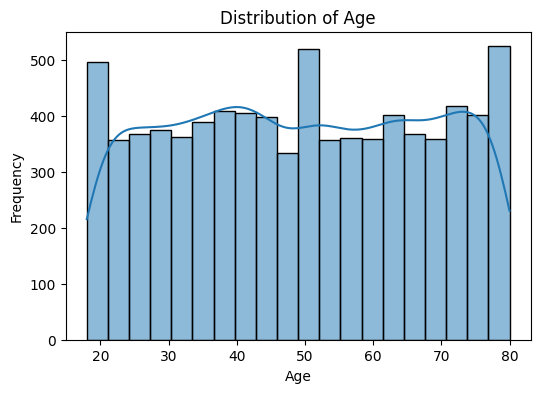


Column: Blood Pressure
Skewness: 0.014


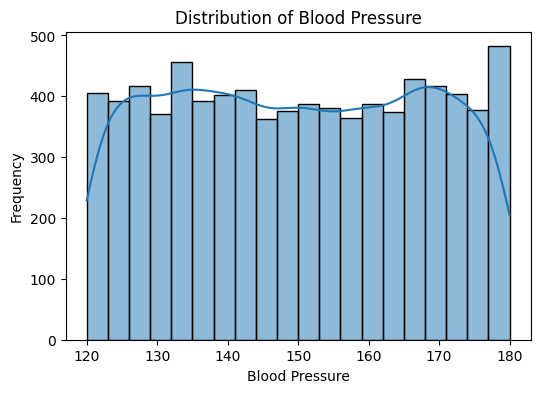


Column: Cholesterol Level
Skewness: -0.015


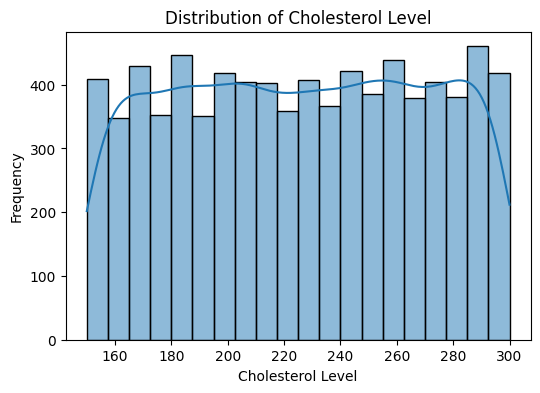


Column: BMI
Skewness: -0.036


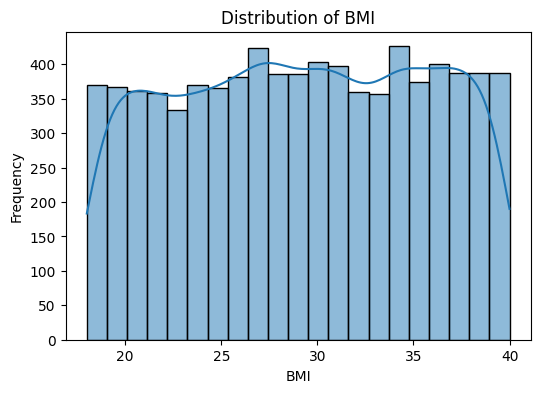


Column: Sleep Hours
Skewness: -0.001


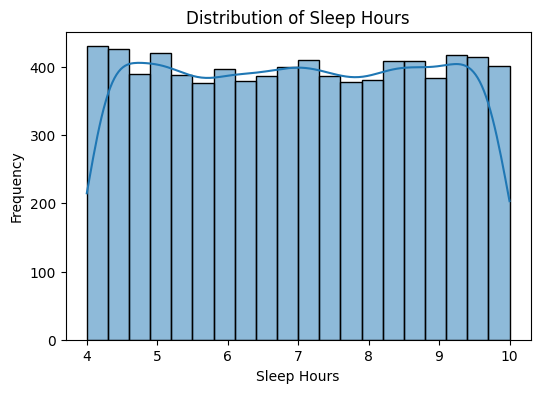


Column: Triglyceride Level
Skewness: -0.002


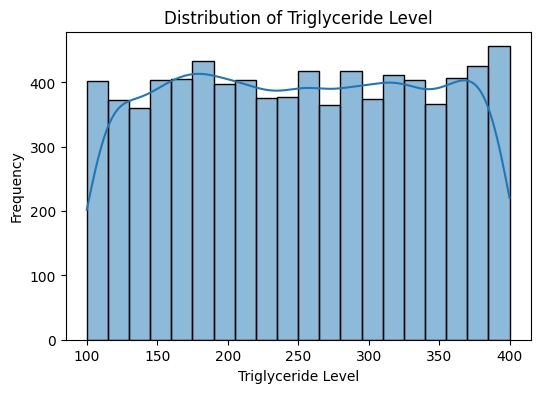


Column: Fasting Blood Sugar
Skewness: -0.012


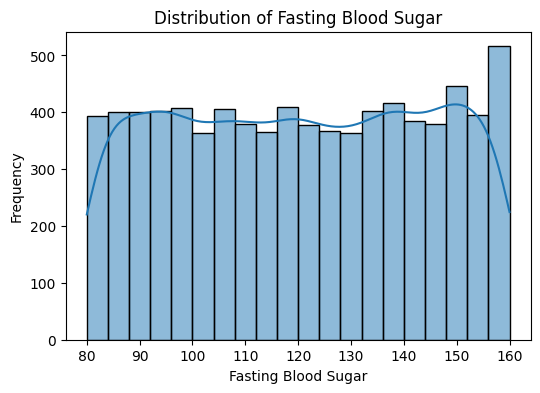


Column: CRP Level
Skewness: -0.001


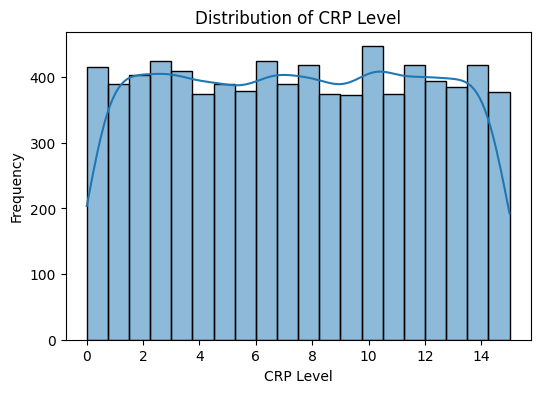


Column: Homocysteine Level
Skewness: 0.020


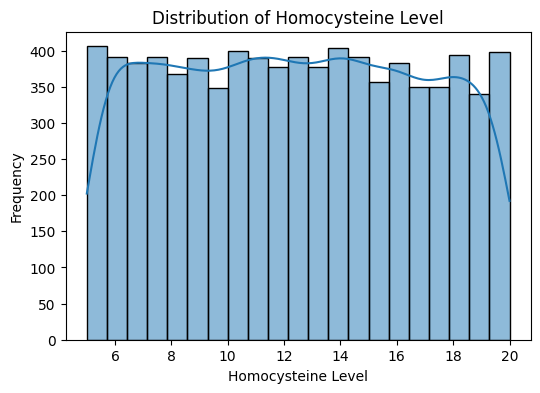

In [28]:
# ============================================
# Distribution Assessment (Numerical Features)
# ============================================

numerical_cols = X_train.select_dtypes(include=np.number).columns

for col in numerical_cols:
    print(f"\nColumn: {col}")
    
    # Skewness
    skew_value = X_train[col].skew()
    print(f"Skewness: {skew_value:.3f}")
    
    # Plot
    plt.figure(figsize=(6,4))
    sns.histplot(X_train[col], kde=True)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.show()

,Column,Outlier Count,Lower Bound,Upper Bound
0,Age,0,-12.500000,111.500000
1,Blood Pressure,0,87.500000,211.500000
2,Cholesterol Level,0,75.500000,375.500000
3,BMI,0,7.538060,50.882576
4,Sleep Hours,0,0.853580,13.129444
5,Triglyceride Level,0,-50.500000,553.500000
6,Fasting Blood Sugar,0,36.000000,204.000000
7,CRP Level,0,-7.682935,22.601839
8,Homocysteine Level,0,-2.449850,27.231295


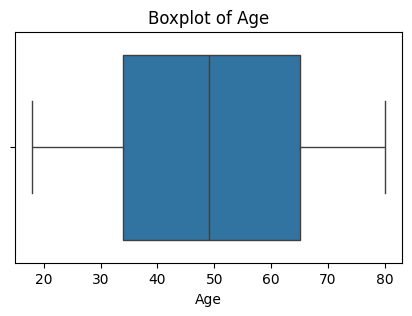

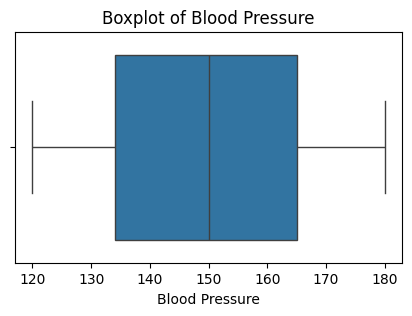

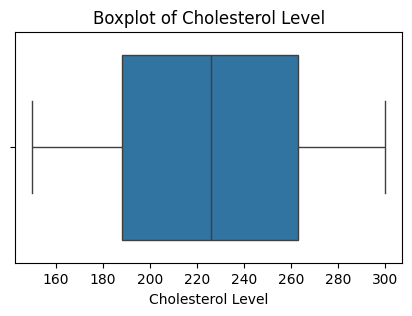

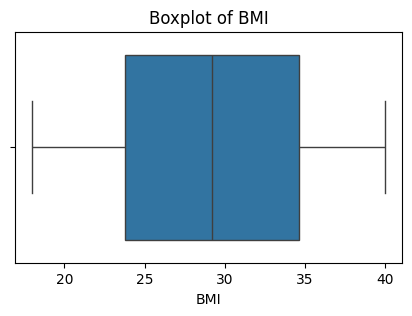

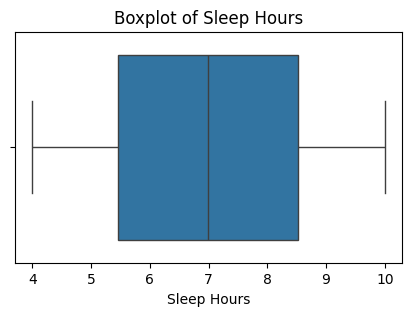

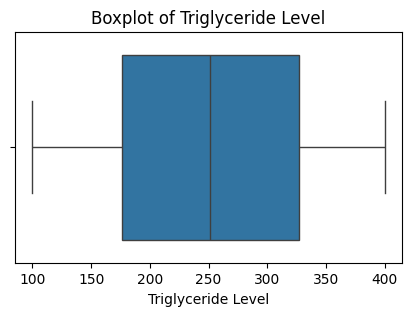

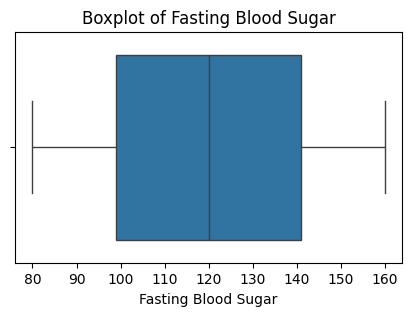

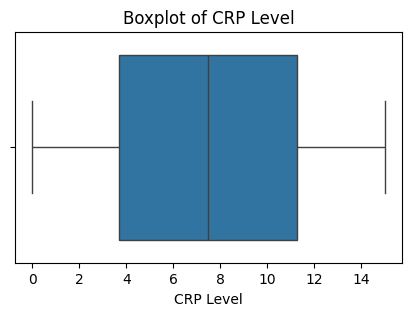

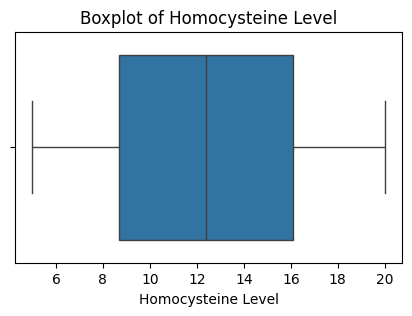

In [29]:
# ============================================
# Outlier Assessment (Numerical Features)
# ============================================

numerical_cols = X_train.select_dtypes(include=np.number).columns

outlier_summary = []

for col in numerical_cols:
    Q1 = X_train[col].quantile(0.25)
    Q3 = X_train[col].quantile(0.75)
    IQR = Q3 - Q1
    
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    outliers = X_train[(X_train[col] < lower_bound) | (X_train[col] > upper_bound)]
    
    outlier_summary.append({
        'Column': col,
        'Outlier Count': outliers.shape[0],
        'Lower Bound': lower_bound,
        'Upper Bound': upper_bound
    })

outlier_df = pd.DataFrame(outlier_summary)

display(outlier_df.sort_values(by='Outlier Count', ascending=False))


# ======================
# Boxplots
# ======================

for col in numerical_cols:
    plt.figure(figsize=(5,3))
    sns.boxplot(x=X_train[col])
    plt.title(f"Boxplot of {col}")
    plt.show()

In [30]:
# ============================================
# Numerical Range Check (Min / Max Values)
# ============================================

numerical_cols = X_train.select_dtypes(include=np.number).columns

range_summary = []

for col in numerical_cols:
    range_summary.append({
        'Column': col,
        'Min Value': X_train[col].min(),
        'Max Value': X_train[col].max(),
        'Mean': X_train[col].mean(),
        'Median': X_train[col].median()
    })

range_df = pd.DataFrame(range_summary)

display(range_df.sort_values(by='Min Value'))

,Column,Min Value,Max Value,Mean,Median
7,CRP Level,0.003647,14.997087,7.473719,7.472216
4,Sleep Hours,4.000605,9.999952,6.991151,6.997215
8,Homocysteine Level,5.000236,19.999037,12.421724,12.381936
0,Age,18.000000,80.000000,49.251630,49.000000
3,BMI,18.002837,39.996954,29.159816,29.197439
6,Fasting Blood Sugar,80.000000,160.000000,120.231801,120.000000
5,Triglyceride Level,100.000000,400.000000,251.225871,251.000000
1,Blood Pressure,120.000000,180.000000,149.689072,150.000000
2,Cholesterol Level,150.000000,300.000000,225.657852,226.000000


In [32]:
# ============================================
# Categorical Encoding (Manual Demonstration)
# ============================================

# Create copies from missing-handled data (do NOT modify original data)
X_train_encoded_manual = X_train_manual.copy()
X_test_encoded_manual = X_test_manual.copy()

# ----------------------
# Binary Encoding (Yes/No -> 1/0)
# ----------------------
binary_cols = [
    'Smoking',
    'Family Heart Disease',
    'Diabetes',
    'High Blood Pressure',
    'Low HDL Cholesterol',
    'High LDL Cholesterol'
]

binary_mapping = {'No': 0, 'Yes': 1}

for col in binary_cols:
    X_train_encoded_manual[col] = X_train_encoded_manual[col].map(binary_mapping)
    X_test_encoded_manual[col] = X_test_encoded_manual[col].map(binary_mapping)

# ----------------------
# Ordinal Encoding (Low/Medium/High -> 0/1/2)
# ----------------------
ordinal_cols = [
    'Exercise Habits',
    'Stress Level',
    'Sugar Consumption'
]

ordinal_mapping = {'Low': 0, 'Medium': 1, 'High': 2}

for col in ordinal_cols:
    X_train_encoded_manual[col] = X_train_encoded_manual[col].map(ordinal_mapping)
    X_test_encoded_manual[col] = X_test_encoded_manual[col].map(ordinal_mapping)

# ----------------------
# Nominal Encoding (One-Hot for Gender and Alcohol Consumption)
# ----------------------
nominal_cols = ['Gender', 'Alcohol Consumption']

X_train_encoded_manual = pd.get_dummies(
    X_train_encoded_manual,
    columns=nominal_cols,
    drop_first=True
)

X_test_encoded_manual = pd.get_dummies(
    X_test_encoded_manual,
    columns=nominal_cols,
    drop_first=True
)

# ----------------------
# Align train and test columns
# ----------------------
X_train_encoded_manual, X_test_encoded_manual = X_train_encoded_manual.align(
    X_test_encoded_manual,
    join='left',
    axis=1,
    fill_value=0
)

# ----------------------
# Convert boolean columns to integers
# ----------------------
bool_cols_train = X_train_encoded_manual.select_dtypes(include='bool').columns
bool_cols_test = X_test_encoded_manual.select_dtypes(include='bool').columns

X_train_encoded_manual[bool_cols_train] = X_train_encoded_manual[bool_cols_train].astype(int)
X_test_encoded_manual[bool_cols_test] = X_test_encoded_manual[bool_cols_test].astype(int)

# ----------------------
# Check result
# ----------------------
print("Encoded train sample:")
display(X_train_encoded_manual.head())

Encoded train sample:


,Age,Blood Pressure,Cholesterol Level,Exercise Habits,Smoking,Family Heart Disease,Diabetes,BMI,High Blood Pressure,Low HDL Cholesterol,...,Sleep Hours,Sugar Consumption,Triglyceride Level,Fasting Blood Sugar,CRP Level,Homocysteine Level,Gender_Male,Alcohol Consumption_Low,Alcohol Consumption_Medium,Alcohol Consumption_Missing
7395,19.0,175.0,272.0,2,0,1,0,28.879776,1,1,...,9.336435,2,201.0,159.0,5.826202,17.965483,1,1,0,0
5642,22.0,123.0,170.0,2,0,0,0,30.256079,0,1,...,6.997215,0,335.0,122.0,3.209347,7.662533,0,0,1,0
8866,45.0,158.0,172.0,1,1,1,1,33.965395,1,0,...,8.946560,0,377.0,109.0,13.295242,19.739923,0,0,0,1
8517,29.0,143.0,292.0,0,1,0,1,21.565885,0,1,...,9.851365,1,370.0,120.0,0.691456,12.739675,1,0,0,0
3706,46.0,135.0,224.0,0,0,1,0,28.271290,0,0,...,7.965155,2,351.0,149.0,10.908451,18.198180,0,0,0,0


In [33]:
# ============================================
# Scaling (Manual Demonstration)
# ============================================

from sklearn.preprocessing import StandardScaler

# Create copies (do NOT modify previous encoded data)
X_train_scaled_manual = X_train_encoded_manual.copy()
X_test_scaled_manual = X_test_encoded_manual.copy()

# Identify numerical columns (exclude already encoded categorical columns)
numerical_cols = X_train.select_dtypes(include=np.number).columns.tolist()

scaler = StandardScaler()

# Fit on training data only
X_train_scaled_manual[numerical_cols] = scaler.fit_transform(
    X_train_scaled_manual[numerical_cols]
)

# Apply transformation to test data
X_test_scaled_manual[numerical_cols] = scaler.transform(
    X_test_scaled_manual[numerical_cols]
)

# Check result
print("Scaled train sample:")
display(X_train_scaled_manual.head())

Scaled train sample:


,Age,Blood Pressure,Cholesterol Level,Exercise Habits,Smoking,Family Heart Disease,Diabetes,BMI,High Blood Pressure,Low HDL Cholesterol,...,Sleep Hours,Sugar Consumption,Triglyceride Level,Fasting Blood Sugar,CRP Level,Homocysteine Level,Gender_Male,Alcohol Consumption_Low,Alcohol Consumption_Medium,Alcohol Consumption_Missing
7395,-1.662369,1.436939,1.065133,2,0,1,0,-0.044442,1,1,...,1.341143,2,-0.576313,1.643199,-0.380708,1.280252,1,1,0,0
5642,-1.497511,-1.515229,-1.279291,2,0,0,0,0.173925,0,1,...,0.003459,0,0.961279,0.074968,-0.985413,-1.099029,0,0,1,0
8866,-0.233597,0.471808,-1.233322,1,1,1,1,0.762451,1,0,...,1.118193,0,1.443210,-0.476032,1.345242,1.690027,0,0,0,1
8517,-1.112841,-0.379779,1.524824,0,1,0,1,-1.204877,0,1,...,1.635606,1,1.362888,-0.009801,-1.567248,0.073446,1,0,0,0
3706,-0.178645,-0.833959,-0.038126,0,0,1,0,-0.140986,0,0,...,0.556976,2,1.144872,1.219353,0.793701,1.333990,0,0,0,0


In [34]:
# ============================================
# Final Preprocessing Pipeline
# ============================================

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

# ----------------------
# Column groups
# ----------------------
numerical_cols = X_train.select_dtypes(include=np.number).columns.tolist()

binary_cols = [
    'Smoking',
    'Family Heart Disease',
    'Diabetes',
    'High Blood Pressure',
    'Low HDL Cholesterol',
    'High LDL Cholesterol'
]

ordinal_cols = [
    'Exercise Habits',
    'Stress Level',
    'Sugar Consumption'
]

nominal_cols = [
    'Gender',
    'Alcohol Consumption'
]

# ----------------------
# Pipelines for each feature type
# ----------------------
numerical_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

binary_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OrdinalEncoder(categories=[['No', 'Yes']] * len(binary_cols)))
])

ordinal_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OrdinalEncoder(categories=[['Low', 'Medium', 'High']] * len(ordinal_cols)))
])

nominal_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='constant', fill_value='Missing')),
    ('onehot', OneHotEncoder(drop='first', handle_unknown='ignore'))
])

# ----------------------
# ColumnTransformer
# ----------------------
preprocessor = ColumnTransformer(transformers=[
    ('num', numerical_pipeline, numerical_cols),
    ('bin', binary_pipeline, binary_cols),
    ('ord', ordinal_pipeline, ordinal_cols),
    ('nom', nominal_pipeline, nominal_cols)
])

# ----------------------
# Fit on training data only
# ----------------------
X_train_preprocessed = preprocessor.fit_transform(X_train)
X_test_preprocessed = preprocessor.transform(X_test)

print("X_train_preprocessed shape:", X_train_preprocessed.shape)
print("X_test_preprocessed shape:", X_test_preprocessed.shape)

X_train_preprocessed shape: (8000, 23)
X_test_preprocessed shape: (2000, 23)


In [35]:
# ============================================
# Get Feature Names After Preprocessing
# ============================================

# Get feature names from each transformer

# Numerical
num_features = numerical_cols

# Binary
bin_features = binary_cols

# Ordinal
ord_features = ordinal_cols

# Nominal (One-Hot)
nom_features = preprocessor.named_transformers_['nom'] \
    .named_steps['onehot'] \
    .get_feature_names_out(nominal_cols)

# Combine all
all_features = list(num_features) + list(bin_features) + list(ord_features) + list(nom_features)

# Convert to DataFrame
X_train_preprocessed_df = pd.DataFrame(
    X_train_preprocessed,
    columns=all_features
)

X_test_preprocessed_df = pd.DataFrame(
    X_test_preprocessed,
    columns=all_features
)

# Show result
print("Final feature names:")
print(all_features)

print("\nSample of processed data:")
display(X_train_preprocessed_df.head())

Final feature names:
['Age', 'Blood Pressure', 'Cholesterol Level', 'BMI', 'Sleep Hours', 'Triglyceride Level', 'Fasting Blood Sugar', 'CRP Level', 'Homocysteine Level', 'Smoking', 'Family Heart Disease', 'Diabetes', 'High Blood Pressure', 'Low HDL Cholesterol', 'High LDL Cholesterol', 'Exercise Habits', 'Stress Level', 'Sugar Consumption', 'Gender_Male', 'Gender_Missing', 'Alcohol Consumption_Low', 'Alcohol Consumption_Medium', 'Alcohol Consumption_Missing']

Sample of processed data:


,Age,Blood Pressure,Cholesterol Level,BMI,Sleep Hours,Triglyceride Level,Fasting Blood Sugar,CRP Level,Homocysteine Level,Smoking,...,Low HDL Cholesterol,High LDL Cholesterol,Exercise Habits,Stress Level,Sugar Consumption,Gender_Male,Gender_Missing,Alcohol Consumption_Low,Alcohol Consumption_Medium,Alcohol Consumption_Missing
0,-1.662369,1.436939,1.065133,-0.044442,1.341143,-0.576313,1.643199,-0.380708,1.280252,0.0,...,1.0,0.0,2.0,0.0,2.0,1.0,0.0,1.0,0.0,0.0
1,-1.497511,-1.515229,-1.279291,0.173925,0.003459,0.961279,0.074968,-0.985413,-1.099029,0.0,...,1.0,1.0,2.0,2.0,0.0,0.0,0.0,0.0,1.0,0.0
2,-0.233597,0.471808,-1.233322,0.762451,1.118193,1.443210,-0.476032,1.345242,1.690027,1.0,...,0.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
3,-1.112841,-0.379779,1.524824,-1.204877,1.635606,1.362888,-0.009801,-1.567248,0.073446,1.0,...,1.0,0.0,0.0,2.0,1.0,1.0,0.0,0.0,0.0,0.0
4,-0.178645,-0.833959,-0.038126,-0.140986,0.556976,1.144872,1.219353,0.793701,1.333990,0.0,...,0.0,1.0,0.0,2.0,2.0,0.0,0.0,0.0,0.0,0.0


# Classified ML algorithms

In [36]:
# ============================================
# Logistic Regression (Manual Demonstration)
# ============================================

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

# ----------------------
# Encode target
# ----------------------
y_train_manual = y_train.map({'No': 0, 'Yes': 1})
y_test_manual = y_test.map({'No': 0, 'Yes': 1})

# ----------------------
# Train logistic regression
# ----------------------
log_reg_manual = LogisticRegression(
    random_state=RANDOM_STATE,
    max_iter=1000
)

log_reg_manual.fit(X_train_scaled_manual, y_train_manual)

# ----------------------
# Predictions
# ----------------------
y_pred_manual = log_reg_manual.predict(X_test_scaled_manual)
y_proba_manual = log_reg_manual.predict_proba(X_test_scaled_manual)[:, 1]

# ----------------------
# Confusion matrix values
# ----------------------
tn, fp, fn, tp = confusion_matrix(y_test_manual, y_pred_manual).ravel()

specificity = tn / (tn + fp)

# ----------------------
# Metrics
# ----------------------
print("Logistic Regression (Manual Demonstration)")

print(f"Precision: {precision_score(y_test_manual, y_pred_manual):.4f}")
print(f"Recall: {recall_score(y_test_manual, y_pred_manual):.4f}")
print(f"Specificity: {specificity:.4f}")
print(f"F1 Score: {f1_score(y_test_manual, y_pred_manual):.4f}")
print(f"ROC-AUC: {roc_auc_score(y_test_manual, y_proba_manual):.4f}")
print(f"PR-AUC: {average_precision_score(y_test_manual, y_proba_manual):.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_manual, y_pred_manual))

Logistic Regression (Manual Demonstration)
Precision: 0.0000
Recall: 0.0000
Specificity: 1.0000
F1 Score: 0.0000
ROC-AUC: 0.4710
PR-AUC: 0.1884

Confusion Matrix:
[[1600    0]
 [ 400    0]]


In [37]:
# ============================================
# Logistic Regression with Class Weight (Manual Demonstration)
# ============================================

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

# ----------------------
# Encode target
# ----------------------
y_train_manual = y_train.map({'No': 0, 'Yes': 1})
y_test_manual = y_test.map({'No': 0, 'Yes': 1})

# ----------------------
# Train logistic regression with class_weight='balanced'
# ----------------------
log_reg_manual_balanced = LogisticRegression(
    random_state=RANDOM_STATE,
    max_iter=1000,
    class_weight='balanced'
)

log_reg_manual_balanced.fit(X_train_scaled_manual, y_train_manual)

# ----------------------
# Predictions
# ----------------------
y_pred_manual_balanced = log_reg_manual_balanced.predict(X_test_scaled_manual)
y_proba_manual_balanced = log_reg_manual_balanced.predict_proba(X_test_scaled_manual)[:, 1]

# ----------------------
# Confusion matrix values
# ----------------------
tn, fp, fn, tp = confusion_matrix(y_test_manual, y_pred_manual_balanced).ravel()

specificity = tn / (tn + fp)

# ----------------------
# Metrics
# ----------------------
print("Logistic Regression with Class Weight (Manual Demonstration)")

print(f"Precision: {precision_score(y_test_manual, y_pred_manual_balanced):.4f}")
print(f"Recall: {recall_score(y_test_manual, y_pred_manual_balanced):.4f}")
print(f"Specificity: {specificity:.4f}")
print(f"F1 Score: {f1_score(y_test_manual, y_pred_manual_balanced):.4f}")
print(f"ROC-AUC: {roc_auc_score(y_test_manual, y_proba_manual_balanced):.4f}")
print(f"PR-AUC: {average_precision_score(y_test_manual, y_proba_manual_balanced):.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_manual, y_pred_manual_balanced))

Logistic Regression with Class Weight (Manual Demonstration)
Precision: 0.1802
Recall: 0.4175
Specificity: 0.5250
F1 Score: 0.2517
ROC-AUC: 0.4717
PR-AUC: 0.1890

Confusion Matrix:
[[840 760]
 [233 167]]


In [38]:
# ============================================
# Logistic Regression with Pipeline + Cross-Validation
# ============================================

from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import make_scorer, recall_score
import pandas as pd

# ----------------------
# Encode target
# ----------------------
y_train_encoded = y_train.map({'No': 0, 'Yes': 1})
y_test_encoded = y_test.map({'No': 0, 'Yes': 1})

# ----------------------
# Cross-validation strategy
# ----------------------
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# ----------------------
# Scoring metrics
# ----------------------
scoring = {
    'precision': 'precision',
    'recall': 'recall',
    'f1': 'f1',
    'roc_auc': 'roc_auc',
    'pr_auc': 'average_precision',
    'specificity': make_scorer(recall_score, pos_label=0)
}

# ----------------------
# Pipelines
# ----------------------
log_reg_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', LogisticRegression(
        random_state=RANDOM_STATE,
        max_iter=1000
    ))
])

log_reg_pipeline_balanced = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', LogisticRegression(
        random_state=RANDOM_STATE,
        max_iter=1000,
        class_weight='balanced'
    ))
])

# ----------------------
# Cross-validation
# ----------------------
cv_results_regular = cross_validate(
    log_reg_pipeline,
    X_train,
    y_train_encoded,
    cv=cv,
    scoring=scoring,
    n_jobs=-1,
    return_train_score=False
)

cv_results_balanced = cross_validate(
    log_reg_pipeline_balanced,
    X_train,
    y_train_encoded,
    cv=cv,
    scoring=scoring,
    n_jobs=-1,
    return_train_score=False
)

# ----------------------
# Summary table
# ----------------------
cv_summary = pd.DataFrame({
    'Model': ['Logistic Regression', 'Logistic Regression (Balanced)'],
    'Precision Mean': [cv_results_regular['test_precision'].mean(), cv_results_balanced['test_precision'].mean()],
    'Recall Mean': [cv_results_regular['test_recall'].mean(), cv_results_balanced['test_recall'].mean()],
    'Specificity Mean': [cv_results_regular['test_specificity'].mean(), cv_results_balanced['test_specificity'].mean()],
    'F1 Mean': [cv_results_regular['test_f1'].mean(), cv_results_balanced['test_f1'].mean()],
    'ROC-AUC Mean': [cv_results_regular['test_roc_auc'].mean(), cv_results_balanced['test_roc_auc'].mean()],
    'PR-AUC Mean': [cv_results_regular['test_pr_auc'].mean(), cv_results_balanced['test_pr_auc'].mean()]
})

display(cv_summary)

,Model,Precision Mean,Recall Mean,Specificity Mean,F1 Mean,ROC-AUC Mean,PR-AUC Mean
0,Logistic Regression,0.000000,0.00000,1.000000,0.000000,0.511411,0.210038
1,Logistic Regression (Balanced),0.203811,0.49875,0.513281,0.289309,0.511486,0.209904


In [41]:
# ============================================
# Decision Tree (Regular + Balanced) with Pipeline + GridSearchCV
# ============================================

from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_validate
from sklearn.metrics import make_scorer, recall_score
import pandas as pd

# ----------------------
# Encode target
# ----------------------
y_train_encoded = y_train.map({'No': 0, 'Yes': 1})

# ----------------------
# Cross-validation strategy
# ----------------------
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# ----------------------
# Scoring metrics
# ----------------------
scoring = {
    'precision': 'precision',
    'recall': 'recall',
    'specificity': make_scorer(recall_score, pos_label=0),
    'f1': 'f1',
    'roc_auc': 'roc_auc',
    'pr_auc': 'average_precision'
}

# ----------------------
# Base pipeline
# ----------------------
dt_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', DecisionTreeClassifier(random_state=RANDOM_STATE))
])

# ----------------------
# Hyperparameter grids
# ----------------------
param_grid_regular = {
    'model__max_depth': [3, 5, 10, None],
    'model__min_samples_split': [2, 5, 10],
    'model__min_samples_leaf': [1, 2, 5]
}

param_grid_balanced = {
    'model__max_depth': [3, 5, 10, None],
    'model__min_samples_split': [2, 5, 10],
    'model__min_samples_leaf': [1, 2, 5],
    'model__class_weight': ['balanced']
}

# ----------------------
# Grid search: regular
# ----------------------
grid_dt_regular = GridSearchCV(
    estimator=dt_pipeline,
    param_grid=param_grid_regular,
    scoring='average_precision',
    cv=cv,
    n_jobs=-1,
    refit=True,
    verbose=1
)

grid_dt_regular.fit(X_train, y_train_encoded)

# ----------------------
# Grid search: balanced
# ----------------------
grid_dt_balanced = GridSearchCV(
    estimator=dt_pipeline,
    param_grid=param_grid_balanced,
    scoring='average_precision',
    cv=cv,
    n_jobs=-1,
    refit=True,
    verbose=1
)

grid_dt_balanced.fit(X_train, y_train_encoded)

# ----------------------
# Cross-validation on best estimators
# ----------------------
cv_results_regular = cross_validate(
    estimator=grid_dt_regular.best_estimator_,
    X=X_train,
    y=y_train_encoded,
    cv=cv,
    scoring=scoring,
    n_jobs=-1,
    return_train_score=False
)

cv_results_balanced = cross_validate(
    estimator=grid_dt_balanced.best_estimator_,
    X=X_train,
    y=y_train_encoded,
    cv=cv,
    scoring=scoring,
    n_jobs=-1,
    return_train_score=False
)

# ----------------------
# Summary table
# ----------------------
dt_summary = pd.DataFrame({
    'Model': ['Decision Tree', 'Decision Tree (Balanced)'],
    'Precision Mean': [
        cv_results_regular['test_precision'].mean(),
        cv_results_balanced['test_precision'].mean()
    ],
    'Recall Mean': [
        cv_results_regular['test_recall'].mean(),
        cv_results_balanced['test_recall'].mean()
    ],
    'Specificity Mean': [
        cv_results_regular['test_specificity'].mean(),
        cv_results_balanced['test_specificity'].mean()
    ],
    'F1 Mean': [
        cv_results_regular['test_f1'].mean(),
        cv_results_balanced['test_f1'].mean()
    ],
    'ROC-AUC Mean': [
        cv_results_regular['test_roc_auc'].mean(),
        cv_results_balanced['test_roc_auc'].mean()
    ],
    'PR-AUC Mean': [
        cv_results_regular['test_pr_auc'].mean(),
        cv_results_balanced['test_pr_auc'].mean()
    ],
    'Best Parameters': [
        str(grid_dt_regular.best_params_),
        str(grid_dt_balanced.best_params_)
    ]
})

display(dt_summary)

Fitting 5 folds for each of 36 candidates, totalling 180 fits
Fitting 5 folds for each of 36 candidates, totalling 180 fits


,Model,Precision Mean,Recall Mean,Specificity Mean,F1 Mean,ROC-AUC Mean,PR-AUC Mean,Best Parameters
0,Decision Tree,0.237879,0.006250,0.995938,0.012166,0.503545,0.206034,"{'model__max_depth': 5, 'model__min_samples_le..."
1,Decision Tree (Balanced),0.214298,0.438125,0.593281,0.281070,0.517015,0.210813,"{'model__class_weight': 'balanced', 'model__ma..."


In [42]:
# ============================================
# Random Forest (Regular + Balanced) with Pipeline + GridSearchCV
# ============================================

from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_validate
from sklearn.metrics import make_scorer, recall_score
import pandas as pd

# ----------------------
# Encode target
# ----------------------
y_train_encoded = y_train.map({'No': 0, 'Yes': 1})

# ----------------------
# Cross-validation strategy
# ----------------------
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# ----------------------
# Scoring metrics
# ----------------------
scoring = {
    'precision': 'precision',
    'recall': 'recall',
    'specificity': make_scorer(recall_score, pos_label=0),
    'f1': 'f1',
    'roc_auc': 'roc_auc',
    'pr_auc': 'average_precision'
}

# ----------------------
# Base pipeline
# ----------------------
rf_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1))
])

# ----------------------
# Hyperparameter grids
# ----------------------
param_grid_regular = {
    'model__n_estimators': [100, 200],
    'model__max_depth': [5, 10, None],
    'model__min_samples_split': [2, 5],
    'model__min_samples_leaf': [1, 2]
}

param_grid_balanced = {
    'model__n_estimators': [100, 200],
    'model__max_depth': [5, 10, None],
    'model__min_samples_split': [2, 5],
    'model__min_samples_leaf': [1, 2],
    'model__class_weight': ['balanced']
}

# ----------------------
# Grid search: regular
# ----------------------
grid_rf_regular = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=param_grid_regular,
    scoring='average_precision',
    cv=cv,
    n_jobs=-1,
    refit=True,
    verbose=1
)

grid_rf_regular.fit(X_train, y_train_encoded)

# ----------------------
# Grid search: balanced
# ----------------------
grid_rf_balanced = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=param_grid_balanced,
    scoring='average_precision',
    cv=cv,
    n_jobs=-1,
    refit=True,
    verbose=1
)

grid_rf_balanced.fit(X_train, y_train_encoded)

# ----------------------
# Cross-validation on best estimators
# ----------------------
cv_results_regular = cross_validate(
    estimator=grid_rf_regular.best_estimator_,
    X=X_train,
    y=y_train_encoded,
    cv=cv,
    scoring=scoring,
    n_jobs=-1,
    return_train_score=False
)

cv_results_balanced = cross_validate(
    estimator=grid_rf_balanced.best_estimator_,
    X=X_train,
    y=y_train_encoded,
    cv=cv,
    scoring=scoring,
    n_jobs=-1,
    return_train_score=False
)

# ----------------------
# Summary table
# ----------------------
rf_summary = pd.DataFrame({
    'Model': ['Random Forest', 'Random Forest (Balanced)'],
    'Precision Mean': [
        cv_results_regular['test_precision'].mean(),
        cv_results_balanced['test_precision'].mean()
    ],
    'Recall Mean': [
        cv_results_regular['test_recall'].mean(),
        cv_results_balanced['test_recall'].mean()
    ],
    'Specificity Mean': [
        cv_results_regular['test_specificity'].mean(),
        cv_results_balanced['test_specificity'].mean()
    ],
    'F1 Mean': [
        cv_results_regular['test_f1'].mean(),
        cv_results_balanced['test_f1'].mean()
    ],
    'ROC-AUC Mean': [
        cv_results_regular['test_roc_auc'].mean(),
        cv_results_balanced['test_roc_auc'].mean()
    ],
    'PR-AUC Mean': [
        cv_results_regular['test_pr_auc'].mean(),
        cv_results_balanced['test_pr_auc'].mean()
    ],
    'Best Parameters': [
        str(grid_rf_regular.best_params_),
        str(grid_rf_balanced.best_params_)
    ]
})

display(rf_summary)

Fitting 5 folds for each of 24 candidates, totalling 120 fits
Fitting 5 folds for each of 24 candidates, totalling 120 fits


,Model,Precision Mean,Recall Mean,Specificity Mean,F1 Mean,ROC-AUC Mean,PR-AUC Mean,Best Parameters
0,Random Forest,0.0,0.0,1.0,0.0,0.503880,0.207090,"{'model__max_depth': None, 'model__min_samples..."
1,Random Forest (Balanced),0.0,0.0,1.0,0.0,0.515023,0.216534,"{'model__class_weight': 'balanced', 'model__ma..."


In [44]:
!pip install xgboost

   ---------------------------------------- 0.0/101.7 MB ? eta -:--:--
   ---------------------------------------- 0.3/101.7 MB ? eta -:--:--
   ---------------------------------------- 1.0/101.7 MB 2.8 MB/s eta 0:00:36
    --------------------------------------- 1.8/101.7 MB 3.1 MB/s eta 0:00:33
    --------------------------------------- 2.4/101.7 MB 3.1 MB/s eta 0:00:33
   - -------------------------------------- 3.4/101.7 MB 3.4 MB/s eta 0:00:30
   - -------------------------------------- 3.9/101.7 MB 3.2 MB/s eta 0:00:31
   - -------------------------------------- 5.0/101.7 MB 3.5 MB/s eta 0:00:28
   -- ------------------------------------- 6.3/101.7 MB 3.9 MB/s eta 0:00:25
   --- ------------------------------------ 7.9/101.7 MB 4.3 MB/s eta 0:00:22
   --- ------------------------------------ 8.9/101.7 MB 4.3 MB/s eta 0:00:22
   ---- ----------------------------------- 10.7/101.7 MB 4.8 MB/s eta 0:00:20
   ---- ----------------------------------- 12.1/101.7 MB 4.9 MB/s eta 0:00:1


[notice] A new release of pip is available: 25.0 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [45]:
# ============================================
# XGBoost (Regular + Weighted) with Pipeline + GridSearchCV
# ============================================

from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_validate
from sklearn.metrics import make_scorer, recall_score
import pandas as pd

# ----------------------
# Encode target
# ----------------------
y_train_encoded = y_train.map({'No': 0, 'Yes': 1})

# ----------------------
# Cross-validation strategy
# ----------------------
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# ----------------------
# Scoring metrics
# ----------------------
scoring = {
    'precision': 'precision',
    'recall': 'recall',
    'specificity': make_scorer(recall_score, pos_label=0),
    'f1': 'f1',
    'roc_auc': 'roc_auc',
    'pr_auc': 'average_precision'
}

# ----------------------
# Compute scale_pos_weight
# ----------------------
neg_count = (y_train_encoded == 0).sum()
pos_count = (y_train_encoded == 1).sum()
scale_pos_weight_value = neg_count / pos_count

# ----------------------
# Base pipeline
# ----------------------
xgb_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', XGBClassifier(
        random_state=RANDOM_STATE,
        eval_metric='logloss',
        n_jobs=-1
    ))
])

# ----------------------
# Hyperparameter grids
# ----------------------
param_grid_regular = {
    'model__n_estimators': [100, 200],
    'model__max_depth': [3, 5, 7],
    'model__learning_rate': [0.01, 0.1],
    'model__subsample': [0.8, 1.0],
    'model__colsample_bytree': [0.8, 1.0]
}

param_grid_weighted = {
    'model__n_estimators': [100, 200],
    'model__max_depth': [3, 5, 7],
    'model__learning_rate': [0.01, 0.1],
    'model__subsample': [0.8, 1.0],
    'model__colsample_bytree': [0.8, 1.0],
    'model__scale_pos_weight': [scale_pos_weight_value]
}

# ----------------------
# Grid search: regular
# ----------------------
grid_xgb_regular = GridSearchCV(
    estimator=xgb_pipeline,
    param_grid=param_grid_regular,
    scoring='average_precision',
    cv=cv,
    n_jobs=-1,
    refit=True,
    verbose=1
)

grid_xgb_regular.fit(X_train, y_train_encoded)

# ----------------------
# Grid search: weighted
# ----------------------
grid_xgb_weighted = GridSearchCV(
    estimator=xgb_pipeline,
    param_grid=param_grid_weighted,
    scoring='average_precision',
    cv=cv,
    n_jobs=-1,
    refit=True,
    verbose=1
)

grid_xgb_weighted.fit(X_train, y_train_encoded)

# ----------------------
# Cross-validation on best estimators
# ----------------------
cv_results_regular = cross_validate(
    estimator=grid_xgb_regular.best_estimator_,
    X=X_train,
    y=y_train_encoded,
    cv=cv,
    scoring=scoring,
    n_jobs=-1,
    return_train_score=False
)

cv_results_weighted = cross_validate(
    estimator=grid_xgb_weighted.best_estimator_,
    X=X_train,
    y=y_train_encoded,
    cv=cv,
    scoring=scoring,
    n_jobs=-1,
    return_train_score=False
)

# ----------------------
# Summary table
# ----------------------
xgb_summary = pd.DataFrame({
    'Model': ['XGBoost', 'XGBoost (Weighted)'],
    'Precision Mean': [
        cv_results_regular['test_precision'].mean(),
        cv_results_weighted['test_precision'].mean()
    ],
    'Recall Mean': [
        cv_results_regular['test_recall'].mean(),
        cv_results_weighted['test_recall'].mean()
    ],
    'Specificity Mean': [
        cv_results_regular['test_specificity'].mean(),
        cv_results_weighted['test_specificity'].mean()
    ],
    'F1 Mean': [
        cv_results_regular['test_f1'].mean(),
        cv_results_weighted['test_f1'].mean()
    ],
    'ROC-AUC Mean': [
        cv_results_regular['test_roc_auc'].mean(),
        cv_results_weighted['test_roc_auc'].mean()
    ],
    'PR-AUC Mean': [
        cv_results_regular['test_pr_auc'].mean(),
        cv_results_weighted['test_pr_auc'].mean()
    ],
    'Best Parameters': [
        str(grid_xgb_regular.best_params_),
        str(grid_xgb_weighted.best_params_)
    ]
})

display(xgb_summary)

Fitting 5 folds for each of 48 candidates, totalling 240 fits
Fitting 5 folds for each of 48 candidates, totalling 240 fits


,Model,Precision Mean,Recall Mean,Specificity Mean,F1 Mean,ROC-AUC Mean,PR-AUC Mean,Best Parameters
0,XGBoost,0.000000,0.000000,1.0000,0.000000,0.509016,0.213889,"{'model__colsample_bytree': 0.8, 'model__learn..."
1,XGBoost (Weighted),0.203637,0.400625,0.6075,0.269868,0.511094,0.214910,"{'model__colsample_bytree': 0.8, 'model__learn..."


In [46]:
# ============================================
# SVM (RBF Kernel: Regular + Balanced) with Pipeline + GridSearchCV
# ============================================

from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_validate
from sklearn.metrics import make_scorer, recall_score
import pandas as pd

# ----------------------
# Encode target
# ----------------------
y_train_encoded = y_train.map({'No': 0, 'Yes': 1})

# ----------------------
# Cross-validation strategy
# ----------------------
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# ----------------------
# Scoring metrics
# ----------------------
scoring = {
    'precision': 'precision',
    'recall': 'recall',
    'specificity': make_scorer(recall_score, pos_label=0),
    'f1': 'f1',
    'roc_auc': 'roc_auc',
    'pr_auc': 'average_precision'
}

# ----------------------
# Base pipeline
# ----------------------
svm_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', SVC(
        kernel='rbf',
        probability=True,
        random_state=RANDOM_STATE
    ))
])

# ----------------------
# Hyperparameter grids
# ----------------------
param_grid_regular = {
    'model__C': [0.01, 0.1, 1, 10, 100],
    'model__gamma': ['scale', 0.001, 0.01, 0.1, 1]
}

param_grid_balanced = {
    'model__C': [0.01, 0.1, 1, 10, 100],
    'model__gamma': ['scale', 0.001, 0.01, 0.1, 1],
    'model__class_weight': ['balanced']
}

# ----------------------
# Grid search: regular
# ----------------------
grid_svm_regular = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=param_grid_regular,
    scoring='average_precision',
    cv=cv,
    n_jobs=-1,
    refit=True,
    verbose=1
)

grid_svm_regular.fit(X_train, y_train_encoded)

# ----------------------
# Grid search: balanced
# ----------------------
grid_svm_balanced = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=param_grid_balanced,
    scoring='average_precision',
    cv=cv,
    n_jobs=-1,
    refit=True,
    verbose=1
)

grid_svm_balanced.fit(X_train, y_train_encoded)

# ----------------------
# Cross-validation on best estimators
# ----------------------
cv_results_regular = cross_validate(
    estimator=grid_svm_regular.best_estimator_,
    X=X_train,
    y=y_train_encoded,
    cv=cv,
    scoring=scoring,
    n_jobs=-1,
    return_train_score=False
)

cv_results_balanced = cross_validate(
    estimator=grid_svm_balanced.best_estimator_,
    X=X_train,
    y=y_train_encoded,
    cv=cv,
    scoring=scoring,
    n_jobs=-1,
    return_train_score=False
)

# ----------------------
# Summary table
# ----------------------
svm_summary = pd.DataFrame({
    'Model': ['SVM (RBF)', 'SVM (RBF, Balanced)'],
    'Precision Mean': [
        cv_results_regular['test_precision'].mean(),
        cv_results_balanced['test_precision'].mean()
    ],
    'Recall Mean': [
        cv_results_regular['test_recall'].mean(),
        cv_results_balanced['test_recall'].mean()
    ],
    'Specificity Mean': [
        cv_results_regular['test_specificity'].mean(),
        cv_results_balanced['test_specificity'].mean()
    ],
    'F1 Mean': [
        cv_results_regular['test_f1'].mean(),
        cv_results_balanced['test_f1'].mean()
    ],
    'ROC-AUC Mean': [
        cv_results_regular['test_roc_auc'].mean(),
        cv_results_balanced['test_roc_auc'].mean()
    ],
    'PR-AUC Mean': [
        cv_results_regular['test_pr_auc'].mean(),
        cv_results_balanced['test_pr_auc'].mean()
    ],
    'Best Parameters': [
        str(grid_svm_regular.best_params_),
        str(grid_svm_balanced.best_params_)
    ]
})

display(svm_summary)

Fitting 5 folds for each of 25 candidates, totalling 125 fits
Fitting 5 folds for each of 25 candidates, totalling 125 fits


,Model,Precision Mean,Recall Mean,Specificity Mean,F1 Mean,ROC-AUC Mean,PR-AUC Mean,Best Parameters
0,SVM (RBF),0.0,0.0,1.0,0.0,0.509131,0.211349,"{'model__C': 10, 'model__gamma': 0.001}"
1,"SVM (RBF, Balanced)",0.0,0.0,1.0,0.0,0.514467,0.213015,"{'model__C': 0.01, 'model__class_weight': 'bal..."
